In [13]:
# Step 1: Import required libraries

import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# Find the project root folder
current_path = Path.cwd()

if (current_path / "outputs").exists():
    project_root = current_path
elif (current_path.parent / "outputs").exists():
    project_root = current_path.parent
else:
    raise FileNotFoundError("Could not find the project outputs folder.")

# Load channel effectiveness results
data_path = project_root / "outputs" / "channel_analysis" / "channel_performance.csv"

channel_data = pd.read_csv(data_path)

# Display the results
print("Channel Effectiveness and ROI Analysis")
display(channel_data)

Channel Effectiveness and ROI Analysis


,channel,total_spend_lkr,incremental_revenue_lkr,spend_share_pct,contribution_share_pct,share_of_total_revenue_pct,roas,current_monthly_spend_lkr,marginal_roas_at_current,adstock_lambda,...,saturation_at_current_pct,roas_rank,contribution_to_spend_index,marginal_roas_rank,roas_p05,roas_median_bootstrap,roas_p95,prob_roas_gt_1,prob_effect_zero,roas_interval_width
0,Outdoor,94057802,5.758258e+08,14.064917,34.617131,18.797504,6.122042,2.782446e+06,1.912807,0.375725,...,67.753507,1,2.461240,1,1.905670,4.653131,7.304909,0.990,0.003,5.399239
1,YouTube,79913729,3.329950e+08,11.949886,20.018784,10.870432,4.166932,2.553402e+06,1.157669,0.110747,...,69.690928,2,1.675228,3,0.097568,3.470083,6.700144,0.895,0.048,6.602575
2,Google Search,119353135,4.869880e+08,17.847451,29.276436,15.897445,4.080228,3.601298e+06,1.266163,0.000097,...,67.542928,3,1.640371,2,0.153094,2.459872,4.781125,0.854,0.032,4.628031
3,TV,156964242,1.540911e+08,23.471621,9.263551,5.030216,0.981696,4.711485e+06,0.483481,0.302474,...,49.230833,4,0.394670,4,0.000000,0.929940,2.222260,0.461,0.099,2.222260
4,Facebook/Instagram,158343617,1.135129e+08,23.677886,6.824099,3.705565,0.716877,4.540711e+06,0.411673,0.075837,...,42.188169,5,0.288206,5,0.000000,1.223191,2.558994,0.605,0.085,2.558994
5,Radio,60107999,0.000000e+00,8.988239,0.000000,0.000000,0.000000,1.834484e+06,0.000000,0.223826,...,NaN,6,0.000000,6,0.000000,1.465944,7.335907,0.552,0.352,7.335907


In [14]:
# Step 2: Compare marketing channel performance

# Select important columns
performance_summary = channel_data[
    [
        "channel",
        "total_spend_lkr",
        "incremental_revenue_lkr",
        "roas",
        "marginal_roas_at_current",
        "prob_roas_gt_1"
    ]
].copy()

# Sort channels by ROAS
performance_summary = performance_summary.sort_values(
    by="roas",
    ascending=False
)

# Display the comparison
display(performance_summary.round(2))


,channel,total_spend_lkr,incremental_revenue_lkr,roas,marginal_roas_at_current,prob_roas_gt_1
0,Outdoor,94057802,5.758258e+08,6.12,1.91,0.99
1,YouTube,79913729,3.329950e+08,4.17,1.16,0.90
2,Google Search,119353135,4.869880e+08,4.08,1.27,0.85
3,TV,156964242,1.540911e+08,0.98,0.48,0.46
4,Facebook/Instagram,158343617,1.135129e+08,0.72,0.41,0.60
5,Radio,60107999,0.000000e+00,0.00,0.00,0.55


### Channel Performance Interpretation

The channel performance analysis compares six advertising channels based on total advertising expenditure, incremental revenue, average Return on Advertising Spend (ROAS), and marginal ROAS.

The results indicate that Outdoor has the highest average ROAS of 6.12, followed by YouTube at 4.17 and Google Search at 4.08. These channels demonstrate stronger estimated revenue returns compared with the other channels.

TV and Facebook/Instagram have lower average ROAS values of 0.98 and 0.72, respectively. Radio has an estimated ROAS of zero in the current analysis and requires further investigation.

The marginal ROAS results provide additional information about the expected return from increasing advertising expenditure. Outdoor has the highest marginal ROAS at 1.91, followed by Google Search at 1.27 and YouTube at 1.16.

These findings suggest that Outdoor, Google Search, and YouTube are promising channels for carefully testing additional investment. However, uncertainty estimates should also be considered before making final budget decisions.

*Note: ROAS measures revenue return rather than profit. The results represent model-based estimates and should not be interpreted as proof of causation.*


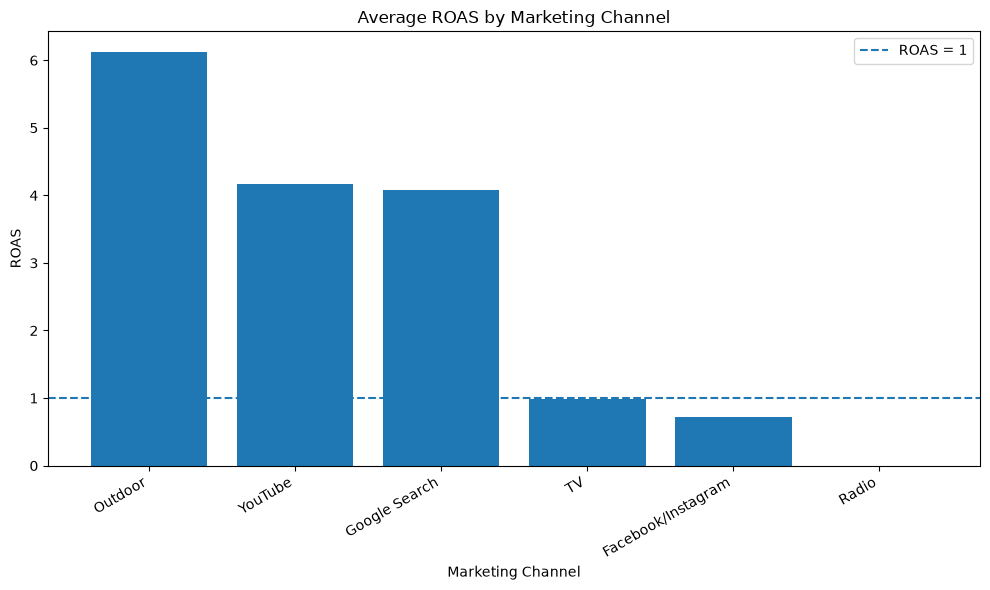

In [15]:
# Step 3: Visualise ROAS by marketing channel

plt.figure(figsize=(10, 6))

# Sort channels by ROAS
roas_data = channel_data.sort_values(
    by="roas",
    ascending=False
)

# Create bar chart
plt.bar(
    roas_data["channel"],
    roas_data["roas"]
)

# Add reference line at ROAS = 1
plt.axhline(
    y=1,
    linestyle="--",
    label="ROAS = 1"
)

# Add chart details
plt.title("Average ROAS by Marketing Channel")
plt.xlabel("Marketing Channel")
plt.ylabel("ROAS")
plt.xticks(rotation=30, ha="right")
plt.legend()

plt.tight_layout()
plt.show()

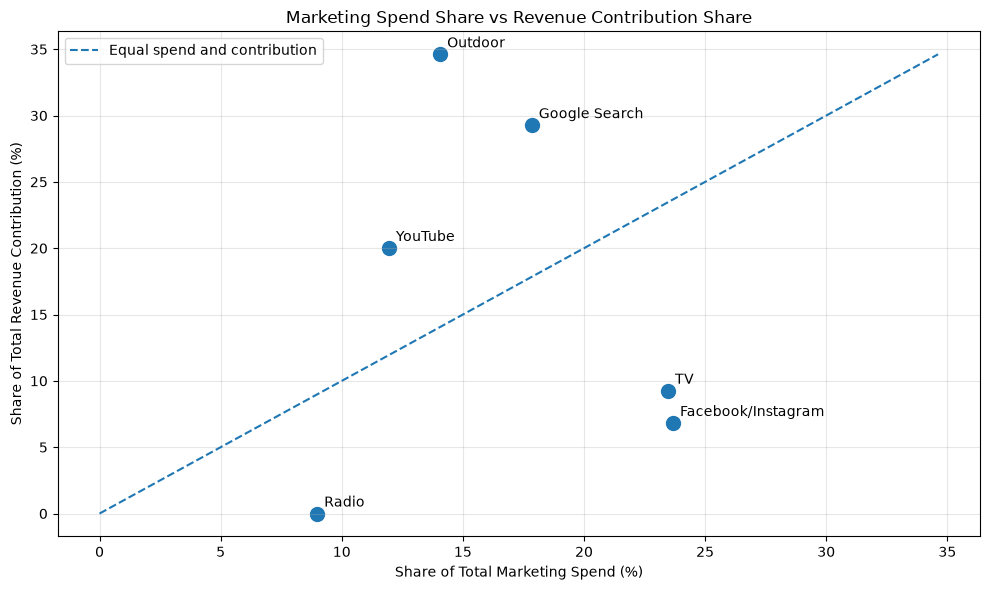

In [16]:
# Step 4: Compare marketing spend and revenue contribution

plt.figure(figsize=(10, 6))

plt.scatter(
    channel_data["spend_share_pct"],
    channel_data["contribution_share_pct"],
    s=100
)

# Add channel names to the chart
for _, row in channel_data.iterrows():
    plt.annotate(
        row["channel"],
        (row["spend_share_pct"], row["contribution_share_pct"]),
        xytext=(5, 5),
        textcoords="offset points"
    )

# Add parity line
max_value = max(
    channel_data["spend_share_pct"].max(),
    channel_data["contribution_share_pct"].max()
)

plt.plot(
    [0, max_value],
    [0, max_value],
    linestyle="--",
    label="Equal spend and contribution"
)

plt.title("Marketing Spend Share vs Revenue Contribution Share")
plt.xlabel("Share of Total Marketing Spend (%)")
plt.ylabel("Share of Total Revenue Contribution (%)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [17]:
# Step 5: Load diminishing returns analysis

diminishing_data_path = (
    project_root / "outputs" / "channel_analysis"
    / "diminishing_returns_analysis.csv"
)

diminishing_data = pd.read_csv(diminishing_data_path)

display(diminishing_data)

,channel,current_monthly_spend_lkr,current_incremental_revenue_lkr,current_marginal_roas,current_average_roas,1_25x_current_incremental_revenue_lkr,1_25x_current_marginal_roas,1_25x_current_average_roas,1_5x_current_incremental_revenue_lkr,1_5x_current_marginal_roas,1_5x_current_average_roas,2x_current_incremental_revenue_lkr,2x_current_marginal_roas,2x_current_average_roas,marginal_roas_decline_at_1_5x_pct,additional_revenue_from_current_to_1_5x_lkr
0,TV,4.711485e+06,4.486810e+06,0.483481,0.952313,4.993880e+06,0.383319,0.847950,5.400788e+06,0.311341,0.764202,6.013247e+06,0.217101,0.638148,35.604362,9.139783e+05
1,Facebook/Instagram,4.540711e+06,3.233398e+06,0.411673,0.712091,3.656134e+06,0.336866,0.644152,4.005231e+06,0.280741,0.588047,4.548055e+06,0.203622,0.500809,31.804747,7.718324e+05
2,Google Search,3.601298e+06,1.404881e+07,1.266163,3.901040,1.502408e+07,0.926759,3.337482,1.575314e+07,0.707559,2.916197,1.677040e+07,0.451063,2.328382,44.117859,1.704336e+06
3,YouTube,2.553402e+06,9.752834e+06,1.157669,3.819545,1.038218e+07,0.839615,3.252816,1.084890e+07,0.636666,2.832535,1.149482e+07,0.402038,2.250884,45.004480,1.096067e+06
4,Radio,1.834484e+06,0.000000e+00,0.000000,0.000000,0.000000e+00,0.000000,0.000000,0.000000e+00,0.000000,0.000000,0.000000e+00,0.000000,0.000000,NaN,0.000000e+00
5,Outdoor,2.782446e+06,1.650500e+07,1.912807,5.931830,1.764283e+07,1.398805,5.072612,1.849275e+07,1.067237,4.430814,1.967768e+07,0.679717,3.536039,44.205723,1.987754e+06


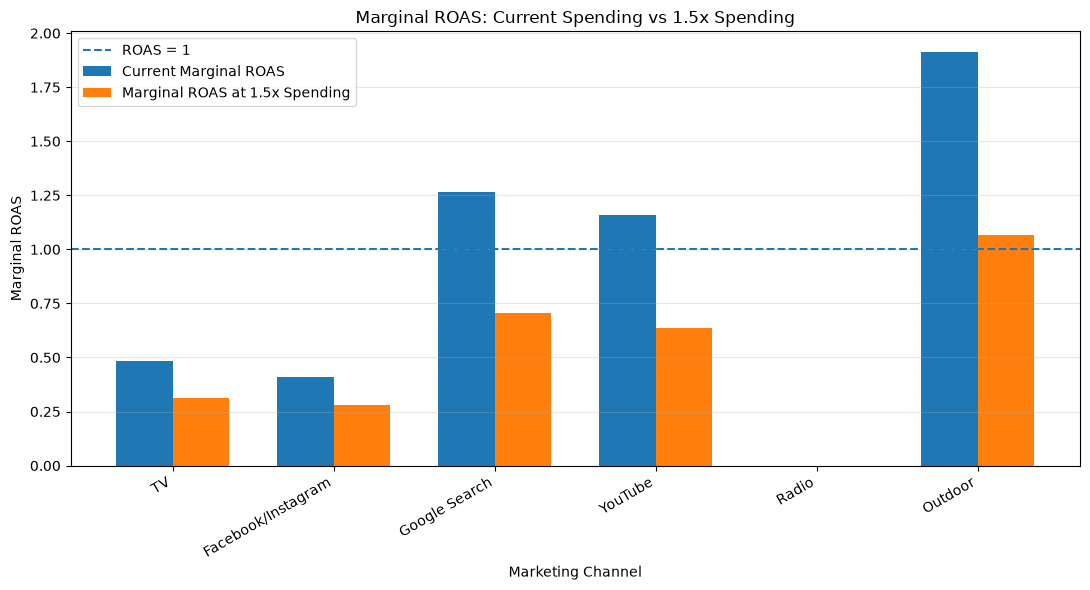

In [18]:
# Step 6: Compare current and 1.5x spending marginal ROAS

plt.figure(figsize=(11, 6))

x = range(len(diminishing_data))
width = 0.35

plt.bar(
    [i - width/2 for i in x],
    diminishing_data["current_marginal_roas"],
    width,
    label="Current Marginal ROAS"
)

plt.bar(
    [i + width/2 for i in x],
    diminishing_data["1_5x_current_marginal_roas"],
    width,
    label="Marginal ROAS at 1.5x Spending"
)

plt.axhline(
    y=1,
    linestyle="--",
    label="ROAS = 1"
)

plt.xticks(
    list(x),
    diminishing_data["channel"],
    rotation=30,
    ha="right"
)

plt.title("Marginal ROAS: Current Spending vs 1.5x Spending")
plt.xlabel("Marketing Channel")
plt.ylabel("Marginal ROAS")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

### Diminishing Returns Analysis – Interpretation

The diminishing returns analysis examines how the expected return from advertising expenditure changes when marketing budgets increase.

The results show that marginal ROAS decreases as spending increases across the marketing channels.

Outdoor has the highest current marginal ROAS of 1.91. At 1.5 times the current spending level, it decreases to approximately 1.07.

Google Search decreases from 1.27 to approximately 0.71, while YouTube decreases from 1.16 to approximately 0.64.

TV and Facebook/Instagram already have marginal ROAS values below 1 at current spending levels.

These findings suggest that increasing advertising expenditure does not always produce proportional revenue growth. Therefore, budget increases should be tested gradually and evaluated using marginal ROAS.

In [19]:
# Step 7: Load channel budget recommendations

recommendations_path = (
    project_root / "outputs" / "channel_analysis"
    / "channel_recommendations.csv"
)

recommendations = pd.read_csv(recommendations_path)

# Display recommendations
display(recommendations)

,channel,roas,marginal_roas_at_current,prob_roas_gt_1,prob_effect_zero,suggested_action,evidence_and_reason
0,Outdoor,6.122042,1.912807,0.990,0.003,Consider gradual testing of additional spend,Average and marginal revenue returns are above...
1,YouTube,4.166932,1.157669,0.895,0.048,Consider gradual testing of additional spend,Average and marginal revenue returns are above...
2,Google Search,4.080228,1.266163,0.854,0.032,Consider gradual testing of additional spend,Average and marginal revenue returns are above...
3,TV,0.981696,0.483481,0.461,0.099,Review and consider reducing or reallocating s...,Both average and next-LKR revenue returns are ...
4,Facebook/Instagram,0.716877,0.411673,0.605,0.085,Review and consider reducing or reallocating s...,Both average and next-LKR revenue returns are ...
5,Radio,0.000000,0.000000,0.552,0.352,Investigate before reallocating,The bootstrap assigns meaningful probability t...


In [20]:
# Step 8: Display channel recommendations

for _, row in recommendations.iterrows():

    print("Channel:", row["channel"])

    print("ROAS:", round(row["roas"], 2))

    print("Marginal ROAS:", round(
        row["marginal_roas_at_current"], 2
    ))

    print("Suggested Action:", row["suggested_action"])

    print("Reason:", row["evidence_and_reason"])

    print("-" * 70)

Channel: Outdoor
ROAS: 6.12
Marginal ROAS: 1.91
Suggested Action: Consider gradual testing of additional spend
Reason: Average and marginal revenue returns are above 1, with relatively strong bootstrap support. Increase in controlled steps and monitor.
----------------------------------------------------------------------
Channel: YouTube
ROAS: 4.17
Marginal ROAS: 1.16
Suggested Action: Consider gradual testing of additional spend
Reason: Average and marginal revenue returns are above 1, with relatively strong bootstrap support. Increase in controlled steps and monitor.
----------------------------------------------------------------------
Channel: Google Search
ROAS: 4.08
Marginal ROAS: 1.27
Suggested Action: Consider gradual testing of additional spend
Reason: Average and marginal revenue returns are above 1, with relatively strong bootstrap support. Increase in controlled steps and monitor.
----------------------------------------------------------------------
Channel: TV
ROAS: 0.98

### Marketing Budget Recommendations

Based on the channel effectiveness and marginal ROAS analysis, different budget strategies are recommended for the six marketing channels.

**1. Outdoor:** Outdoor demonstrates the strongest performance, with an average ROAS of 6.12 and marginal ROAS of 1.91. Gradually testing additional investment is recommended.

**2. YouTube:** YouTube achieves an average ROAS of 4.17 and marginal ROAS of 1.16. Additional spending can be tested carefully while monitoring performance.

**3. Google Search:** Google Search achieves an average ROAS of 4.08 and marginal ROAS of 1.27. Controlled budget increases may be considered.

**4. TV:** TV has an average ROAS of 0.98 and marginal ROAS of 0.48. Its spending should be reviewed before making allocation decisions.

**5. Facebook/Instagram:** Facebook/Instagram has an average ROAS of 0.72 and marginal ROAS of 0.41. The channel requires performance review and possible budget reallocation.

**6. Radio:** Radio has an estimated ROAS of zero in the current analysis. Further investigation of channel activity, data quality and model uncertainty is recommended before reallocating its budget.

Overall, the analysis suggests prioritising controlled investment tests in Outdoor, YouTube and Google Search while reviewing lower-return channels. Budget decisions should also consider uncertainty, business objectives and the diminishing returns associated with increased expenditure.

channel_roas_with_uncertainty.png


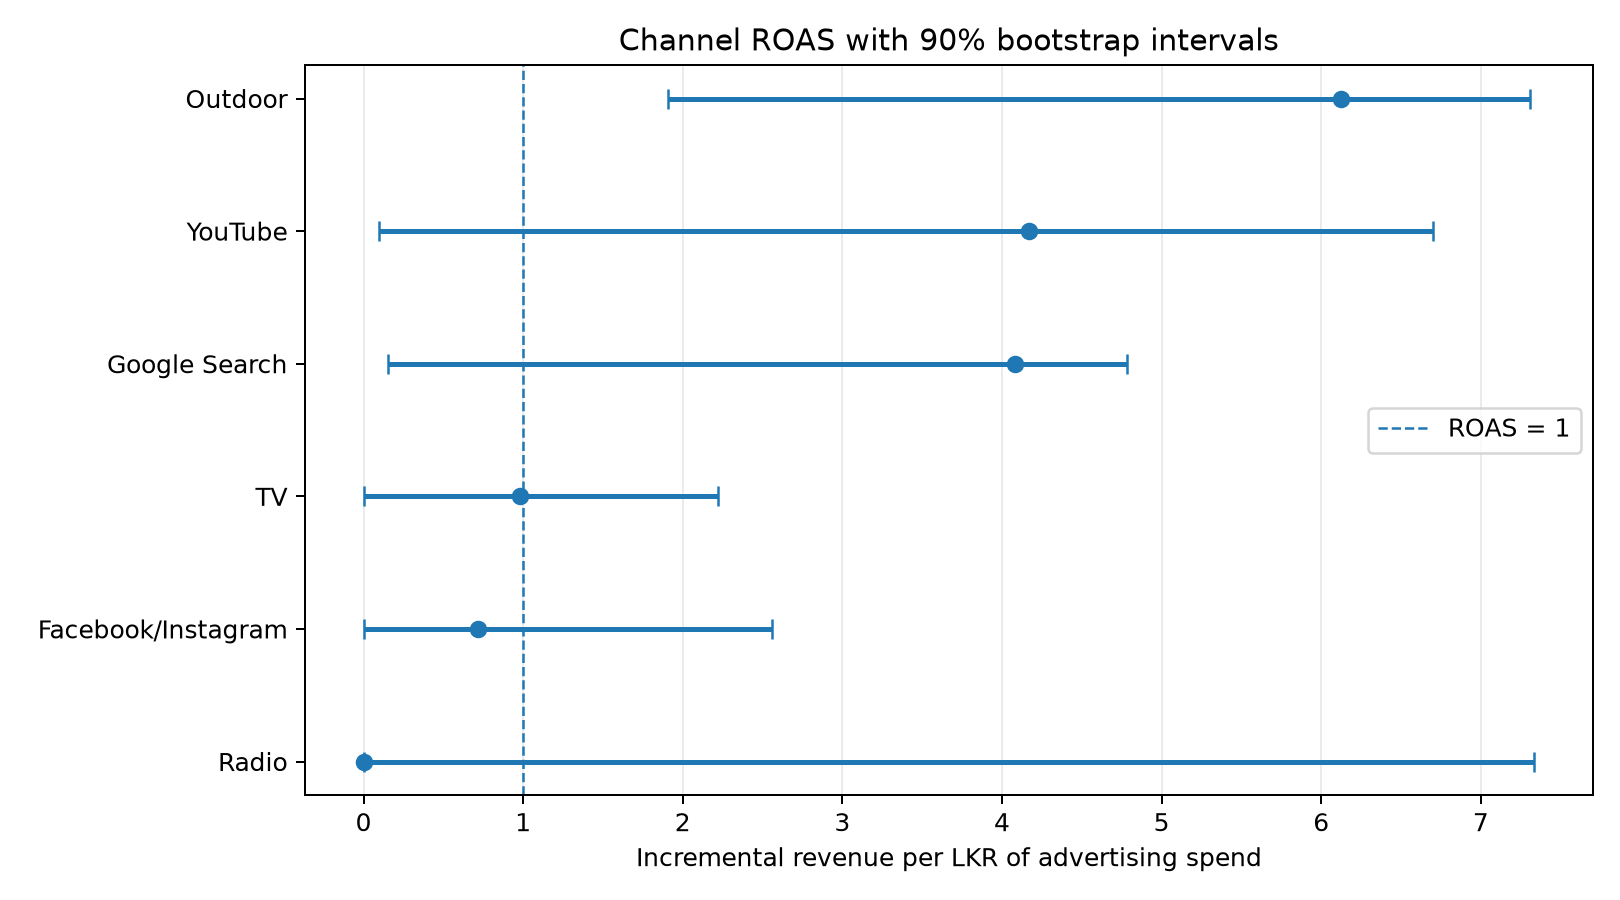

channel_spend_vs_contribution.png


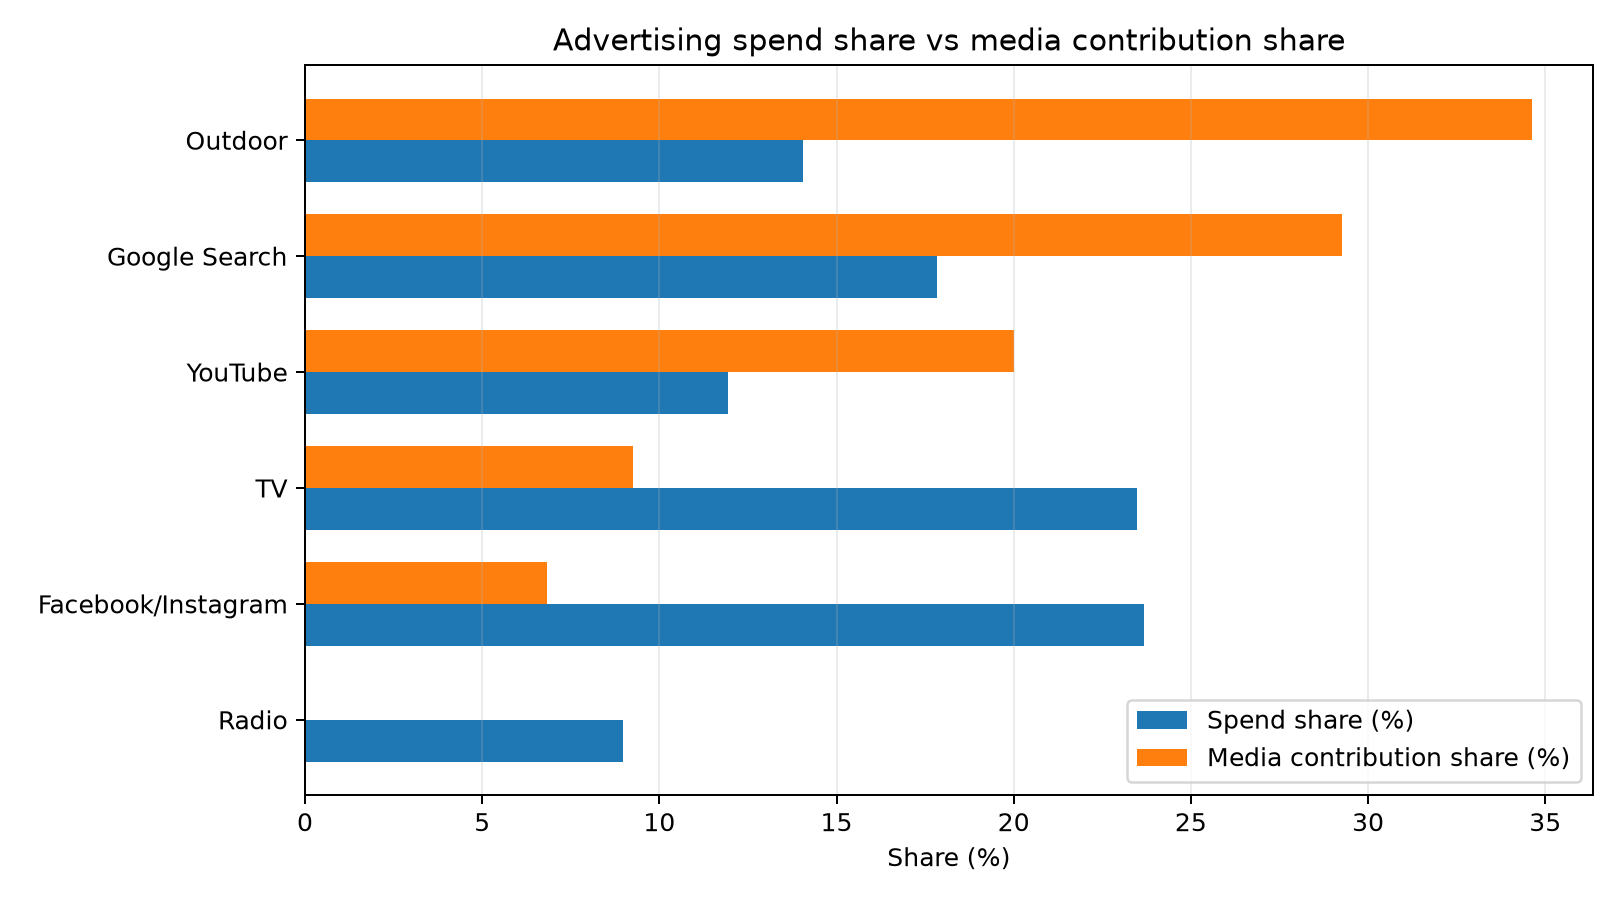

channel_diminishing_returns.png


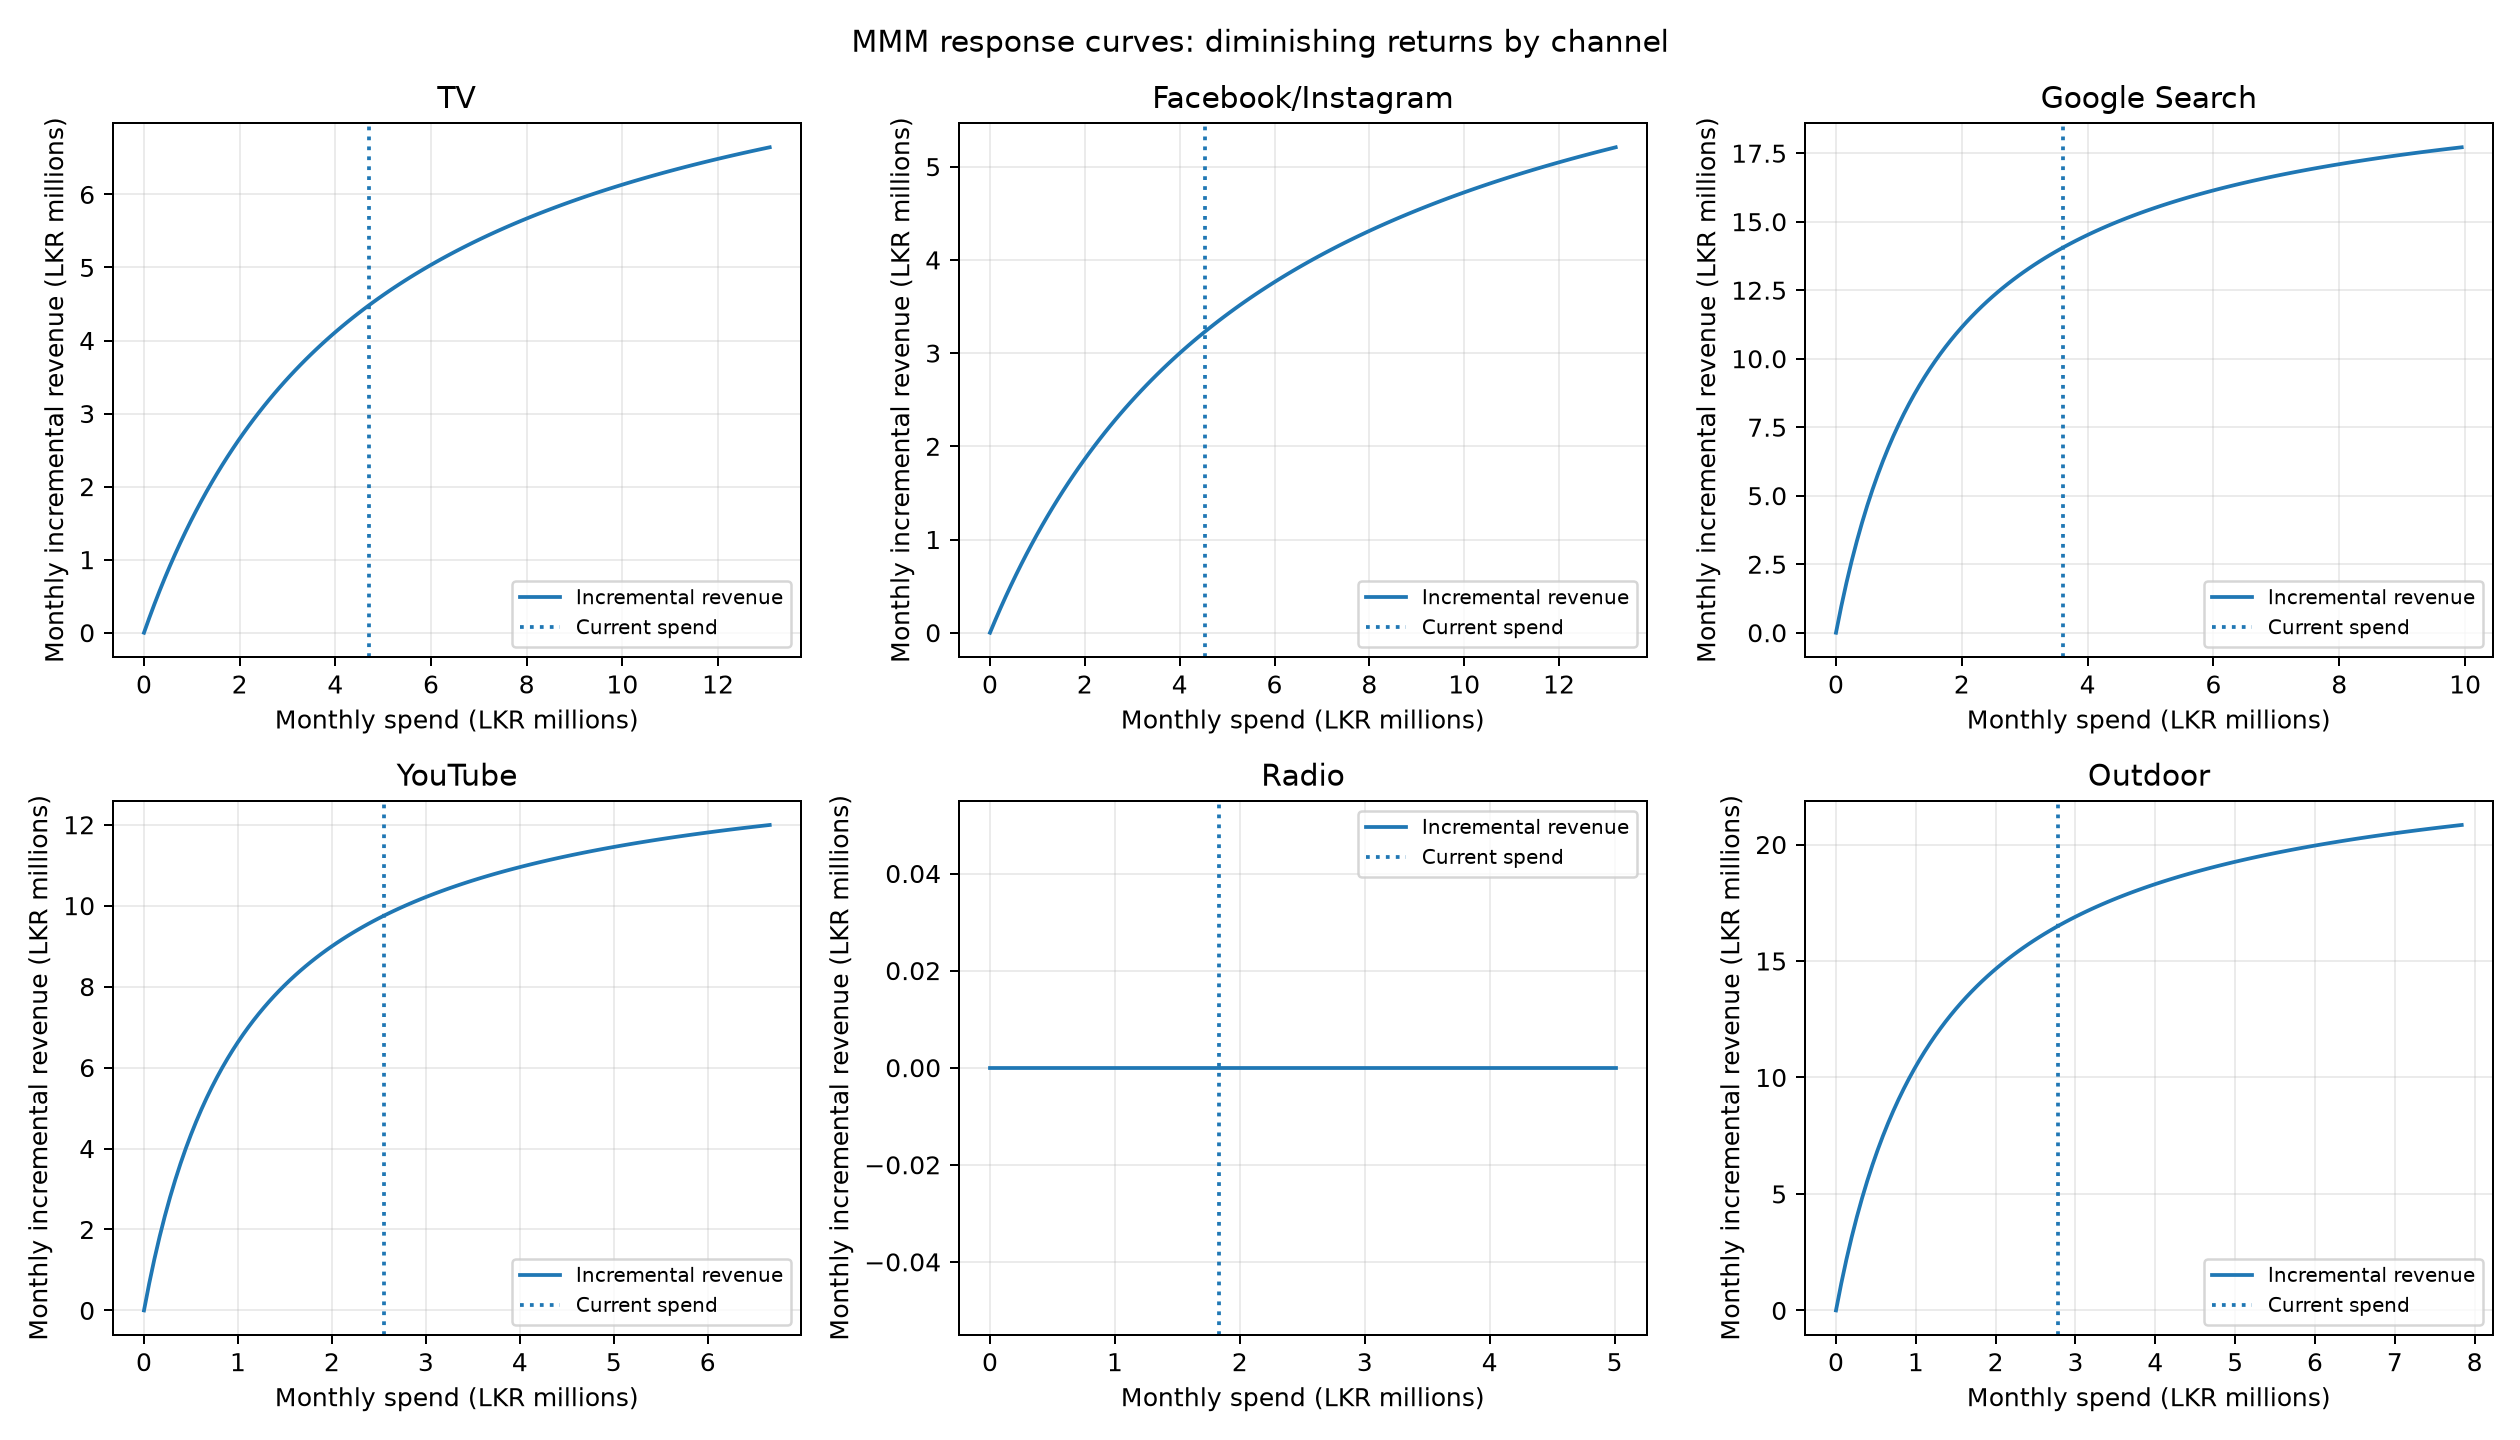

channel_marginal_roas_scenarios.png


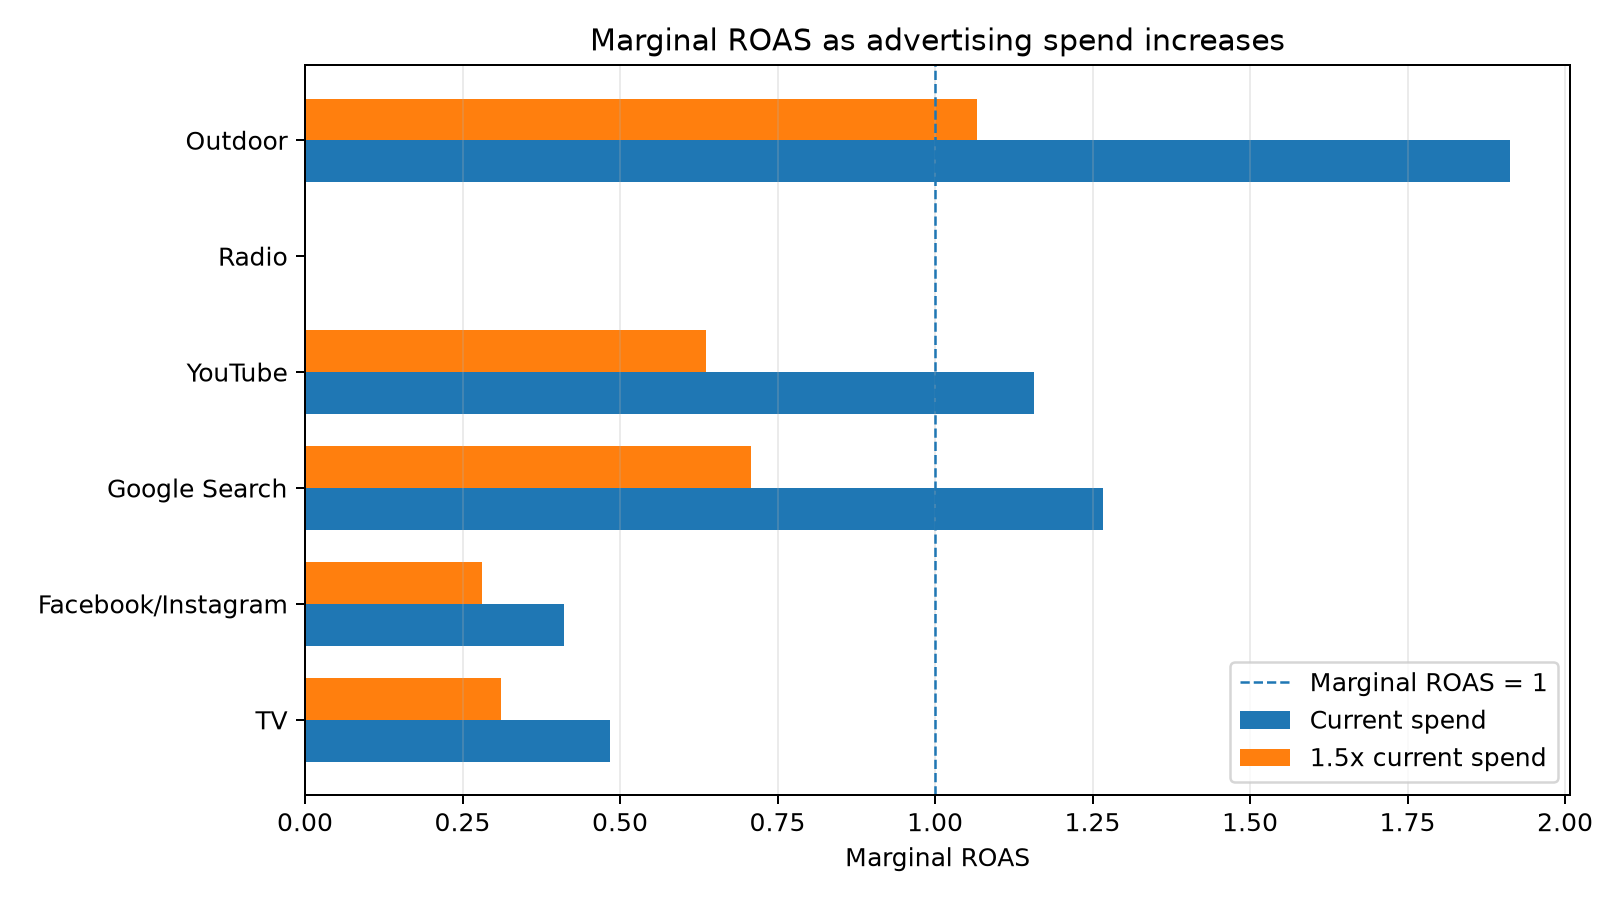

In [21]:
# Step 9: Display all existing analysis charts

from IPython.display import Image, display

chart_folder = project_root / "reports" / "figures"

chart_files = [
    "channel_roas_with_uncertainty.png",
    "channel_spend_vs_contribution.png",
    "channel_diminishing_returns.png",
    "channel_marginal_roas_scenarios.png"
]

for chart in chart_files:

    print(chart)

    display(Image(filename=str(chart_folder / chart)))

## Conclusion

This analysis evaluated the effectiveness of six marketing channels using average ROAS, marginal ROAS, revenue contribution, and diminishing returns.

The results indicate that Outdoor achieved the highest average ROAS (6.12) and current marginal ROAS (1.91), making it the strongest-performing channel in the analysis. YouTube and Google Search also demonstrated positive returns and potential for carefully controlled budget increases.

In contrast, TV and Facebook/Instagram recorded average and marginal ROAS values below 1, suggesting that their spending should be reviewed. Radio requires further investigation because the model indicates uncertainty about its contribution.

The diminishing returns analysis shows that marginal ROAS decreases as spending increases. Therefore, budget increases should be gradual and guided by marginal performance rather than average ROAS alone.

Overall, the findings can support more informed marketing budget allocation. However, the results are based on the existing Marketing Mix Model and should be interpreted with uncertainty in mind. ROAS measures revenue generated relative to advertising expenditure and does not represent profit.